Experimental Clip workflow stuff

In [ ]:
import torch
from PIL import Image
from diffusers import AutoPipelineForImage2Image
import matplotlib.pyplot as plt

import base64
import requests
import io

In [ ]:
num_iterations = 20
emotion_set = set(["anger", "disgust", "fear", "happiness", "sadness", "surprise", "neutral"])
target_emotion = "happiness"
model_id = "sd-research/stable-diffusion-v1-1"
initial_image_path = "sad.png"
num_images_per_step = 10

Model Initialization

In [ ]:
# just initializing this in the loop for now, look there for more info
pipe = AutoPipelineForImage2Image.from_pretrained(
    model_id,
    torch_dtype=torch.float32,
    safety_checker=None,        # for some reason flags the angry red emoji as NSFW otherwise😭
    local_files_only=False
).to("cuda")
generator = torch.Generator(device="cuda").manual_seed(42)

Data Preparation

In [ ]:
# CLIP Image and Text from example
if target_emotion not in emotion_set:
    raise ValueError(f"Class '{target_emotion}' is not in the allowed set: {emotion_set}")

initial_image = Image.open(initial_image_path).convert("RGB").resize((256, 256))
text_prompt = f"{target_emotion}"
negative_prompt = f"{emotion_set - set([target_emotion])}"

Inference

In [1]:
# stable diffusion evolutionary example
all_images = []
best_score_per_iteration = []
best_image = None
best_score = -1.0

# loop just to test what happens when generating multiple times
for i in range(num_iterations):
    # might be a ROCM issue, but for some reason the state persists and images just get more and more deformed even when not updating anything between runs without reinitializing the pipeline
    pipe = AutoPipelineForImage2Image.from_pretrained(
        model_id,
        torch_dtype=torch.float32,
        safety_checker=None,        # for some reason flags the angry red emoji as NSFW otherwise😭
        local_files_only=True
    ).to("cuda")


    new_images = pipe(prompt=text_prompt,
                        negative_prompt=negative_prompt,
                        image=initial_image,
                        strength=0.3,           # lower -> more of original image is preserved
                        guidance_scale=6,      # higher -> more faithful to prompt
                        num_inference_steps=50,  # more steps -> better quality
                        num_images_per_prompt=num_images_per_step,  # number of images to generate per prompt
                        height=256, width=256,  # output image size
                        generator=generator,
                    ).images
    all_images.extend(new_images)



    # make request and check for best image
    for idx, img in enumerate(new_images):
        buffer = io.BytesIO()
        img.save(buffer, format="PNG")
        img_bytes = buffer.getvalue()
        image_b64 = base64.b64encode(img_bytes).decode("ascii")
        r = requests.post(
            "http://localhost:8000/predict",
            json={"image": image_b64, "classes": []},
            timeout=30,
        )
        r.raise_for_status()
        result = r.json()
        emotion_score = result["emotions"].get(target_emotion, 0.0)
        if emotion_score > best_score:
            best_score = emotion_score
            best_image = img
    print(f"Iteration {i+1}/{num_iterations}: Score: {best_score:.4f}")

    initial_image = best_image
    best_score_per_iteration.append(best_score)
    if 1 - best_score < 1e-6:  # if score is very close to 1, break early
        break

Iteration 1/20: Score: 0.1420
Iteration 2/20: Score: 0.9988
Iteration 3/20: Score: 0.9988
Iteration 4/20: Score: 0.9988
Iteration 5/20: Score: 0.9988
Iteration 6/20: Score: 0.9988
Iteration 7/20: Score: 0.9988
Iteration 8/20: Score: 0.9988
Iteration 9/20: Score: 0.9988
Iteration 10/20: Score: 0.9988
Iteration 11/20: Score: 0.9988
Iteration 12/20: Score: 0.9988
Iteration 13/20: Score: 0.9988
Iteration 14/20: Score: 0.9988
Iteration 15/20: Score: 0.9988
Iteration 16/20: Score: 0.9988
Iteration 17/20: Score: 0.9991
Iteration 18/20: Score: 0.9991
Iteration 19/20: Score: 0.9991
Iteration 20/20: Score: 0.9991


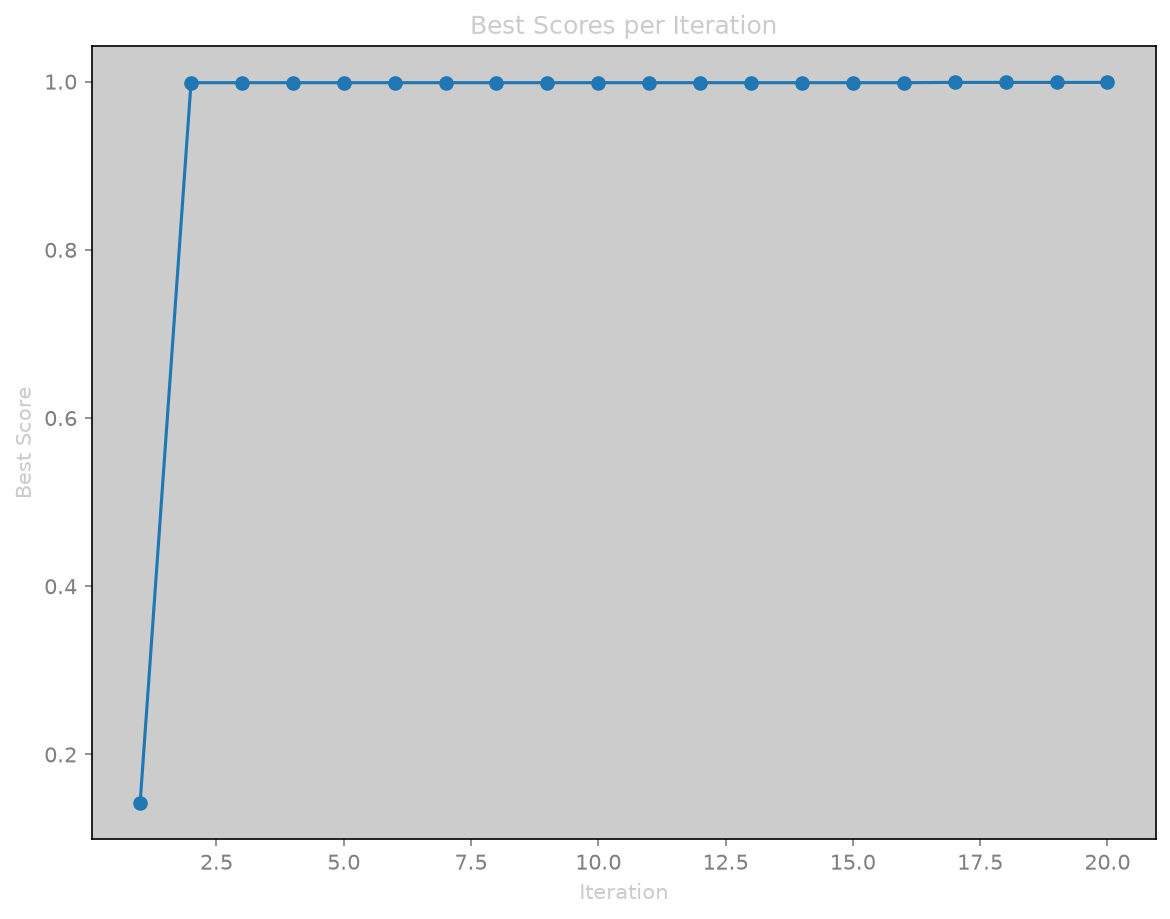

In [2]:
# save best image with score and plot of best scores per iteration
plt.imshow(best_image)
plt.title(f"Best image with score: {best_score}")
plt.axis('off')
plt.savefig("best_image.png")
plt.close()


plt.plot(range(1, len(best_score_per_iteration) + 1), best_score_per_iteration, marker='o')
plt.title("Best Scores per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Best Score")
plt.savefig("best_scores_per_iteration.png")

In [ ]:
# create grid of all generated images
grid_width = num_images_per_step
grid_height = len(all_images) // grid_width + (len(all_images) % grid_width > 0)
grid_image = Image.new('RGB', (grid_width * 256, grid_height * 256))
for idx, img in enumerate(all_images):
    x = (idx % grid_width) * 256
    y = (idx // grid_width) * 256
    grid_image.paste(img, (x, y))

# save the grid image
grid_image.save("output_grid.png")